### **One-Time Pad: Perfect Secrecy and the Danger of Key Reuse**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Cryptography_In_Python/blob/main/Algorithms/One_Time_Pad.ipynb)

> The **one-time pad (OTP)** XORs the message with a truly random key **as long as the message**. Shannon proved in 1949 that it has **perfect secrecy**: the ciphertext reveals nothing except the length. The guarantee holds only if the key is random, secret, and **never reused**; reusing it once (a *two-time pad*) leaks the messages, as the VENONA project showed.

> [!WARNING]
> Educational code. Never use these implementations to protect real data: use a vetted library (for example, `cryptography`) with modern, authenticated algorithms.

In [1]:
# Encryption and decryption are the same XOR operation
import secrets
from collections import Counter

from matplotlib import pyplot as plt

def xor(a, b):
    return bytes(x ^ y for x, y in zip(a, b))

message = b"Meet me at the old bridge at midnight. Bring the documents."
key = secrets.token_bytes(len(message))               # random, as long as the message
ciphertext = xor(message, key)
print("Ciphertext:", ciphertext.hex())
print("Decrypted :", xor(ciphertext, key).decode())
assert xor(ciphertext, key) == message

Ciphertext: f1e8e80d602acbd19c1967e5bff62d64ca1632a81cce5b6c92fe4f9a2ca5e41e93b7af714d33e20476f9780a53f12224736a172609210ee962a92c
Decrypted : Meet me at the old bridge at midnight. Bring the documents.


#### **01. Perfect Secrecy**

For any plaintext of the same length, there is a key that turns the ciphertext into it. An attacker with unlimited computing power still cannot tell which plaintext was sent.

In [2]:
# The same ciphertext "decrypts" to any message of the same length with the right key
fake = b"Stay home tonight, the meeting is cancelled. Burn the plans"
fake = fake[:len(message)].ljust(len(message))
fake_key = xor(ciphertext, fake)
print("With the real key:", xor(ciphertext, key).decode())
print("With another key :", xor(ciphertext, fake_key).decode())

With the real key: Meet me at the old bridge at midnight. Bring the documents.
With another key : Stay home tonight, the meeting is cancelled. Burn the plans


#### **02. Ciphertext Statistics**

The letter frequencies of a long English text are very uneven; the ciphertext bytes of a one-time pad are uniform, so frequency analysis has nothing to work with.

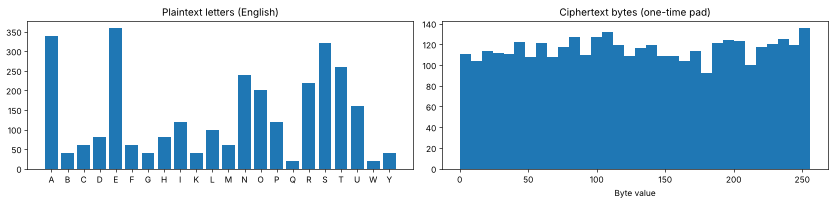

In [3]:
# Letter frequencies of the plaintext vs. byte values of the ciphertext
text = (b"Frequency analysis works because natural language is redundant. Some letters, such as e, t, and a, "
        b"appear far more often than others, and a simple substitution keeps those proportions. ") * 20
pad = secrets.token_bytes(len(text))
cipher_bytes = xor(text, pad)

letter_counts = Counter(chr(b).upper() for b in text if chr(b).isalpha())
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
letters = sorted(letter_counts)
axes[0].bar(letters, [letter_counts[l] for l in letters]); axes[0].set_title("Plaintext letters (English)")
axes[1].hist(list(cipher_bytes), bins=32, range=(0, 256)); axes[1].set_title("Ciphertext bytes (one-time pad)")
axes[1].set_xlabel("Byte value")
plt.tight_layout(); plt.show()

#### **03. Reusing the Key: the Two-Time Pad**

If two messages use the same key, `c1 ⊕ c2 = m1 ⊕ m2`: the key cancels out. Knowing (or guessing) part of one message immediately reveals the same part of the other; knowing one message reveals the other completely.

In [4]:
# Two messages encrypted with the same key
m1 = b"Transfer approved: 50,000 to account 1234-5678 tomorrow 9am."
m2 = b"Board meeting moved to Friday; do not share the merger file."
shared_key = secrets.token_bytes(max(len(m1), len(m2)))
c1, c2 = xor(m1, shared_key), xor(m2, shared_key)

leak = xor(c1, c2)                                   # = m1 XOR m2, no key involved
crib = b"Transfer approved"                           # a guessed start of message 1
print("Guess of message 1 start  :", crib.decode())
print("Reveals message 2 start   :", xor(leak, crib).decode())
print("Knowing all of message 1  :", xor(leak, m1).decode())
assert xor(leak, m1) == m2[:len(m1)]

Guess of message 1 start  : Transfer approved
Reveals message 2 start   : Board meeting mov
Knowing all of message 1  : Board meeting moved to Friday; do not share the merger file.


#### **Key Takeaways**

* The one-time pad is unbreakable only with a truly random key, as long as the message, used once.
* Key distribution is the practical obstacle, which is why stream ciphers and AES-GCM generate keystreams from short keys.
* Never reuse a key or a nonce: the same failure breaks stream ciphers and AES-GCM.